# Digital Device Usage Pattern Analysis Using Machine Learning
**Course:** Advanced Artificial Intelligence — Integrated Practical Assignment  
**Author:** Ahmed Younas — MS Artificial Intelligence, Semester 1  
**Pipeline:** Raw Survey ($N=54$) + Gaussian Copula Expansion ($N=150$) $\rightarrow$ EDA $\rightarrow$ Feature Engineering $\rightarrow$ KNN $\rightarrow$ K-Means $\rightarrow$ Agglomerative (Single, Complete, Average, Ward) $\rightarrow$ Comparative Analysis (`SEED=42`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix,
    silhouette_score, silhouette_samples, adjusted_rand_score, normalized_mutual_info_score
)

SEED = 42
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

cwd = Path.cwd()
base = cwd / "Digital_Device_Usage_Analysis" if (cwd / "Digital_Device_Usage_Analysis").exists() else (cwd if (cwd / "data").exists() else cwd.parent)
def _load_csv(rel_path, flat_name):
    p = base / rel_path
    return pd.read_csv(p if p.exists() else (cwd / flat_name))

df_raw = _load_csv("data/raw/original_responses.csv", "original_responses.csv")
df_comb = _load_csv("data/processed/combined_dataset.csv", "combined_dataset.csv")
df_150 = _load_csv("data/processed/full_150_corrected_features.csv", "full_150_corrected_features.csv")
df_54 = _load_csv("data/processed/genuine_54_corrected_features.csv", "genuine_54_corrected_features.csv")
df_tr_aug = _load_csv("data/splits/train_augmented_features.csv", "train_augmented_features.csv")
df_tr_gen = _load_csv("data/splits/genuine_train_features.csv", "genuine_train_features.csv")
df_test = _load_csv("data/splits/genuine_test_features.csv", "genuine_test_features.csv")

print(f"Raw Genuine: {df_raw.shape} | Combined (54+96): {df_comb.shape} | Corrected Features: {df_150.shape}")
print(f"Leakage-Free Splits -> Genuine Train: {df_tr_gen.shape} | Augmented Train: {df_tr_aug.shape} | Genuine Holdout: {df_test.shape}")
print(f"Missing values (Combined): {df_comb.isna().sum().sum()} | Duplicate rows: {df_comb.duplicated().sum()}")

Raw Genuine: (54, 17) | Combined (54+96): (150, 21) | Corrected Features: (150, 24)
Leakage-Free Splits -> Genuine Train: (38, 24) | Augmented Train: (134, 24) | Genuine Holdout: (16, 24)
Missing values (Combined): 0 | Duplicate rows: 0


## Phase I: Exploratory Data Analysis (EDA)
Inspect representative records, target class balance, numerical distributions, box plots (outliers), correlations, and real-vs-synthetic statistical fidelity.

   daily_device_hours  check_frequency  social_conflict_score  digital_dependency_score  stay_away_difficulty  impact_category data_source
0                   4                5                 3.6667                    4.3333                     4  Moderate Impact        real
1                   2                4                 2.6667                    2.6667                     2      High Impact        real
2                   3                2                 2.3333                    2.3333                     2       Low Impact        real
3                   2                3                 3.0000                    2.3333                     2       Low Impact        real
4                   1                4                 2.0000                    2.3333                     2  Moderate Impact        real
5                   4                5                 4.0000                    4.3333                     4      High Impact        real


<cell>:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
<cell>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,Feature,KS Stat,p-value
0,daily_device_hours,0.0590,0.9989
1,check_frequency,0.0694,0.9910
2,social_conflict_score,0.1516,0.3625
3,digital_dependency_score,0.1551,0.3363
4,stay_away_difficulty,0.0775,0.9727


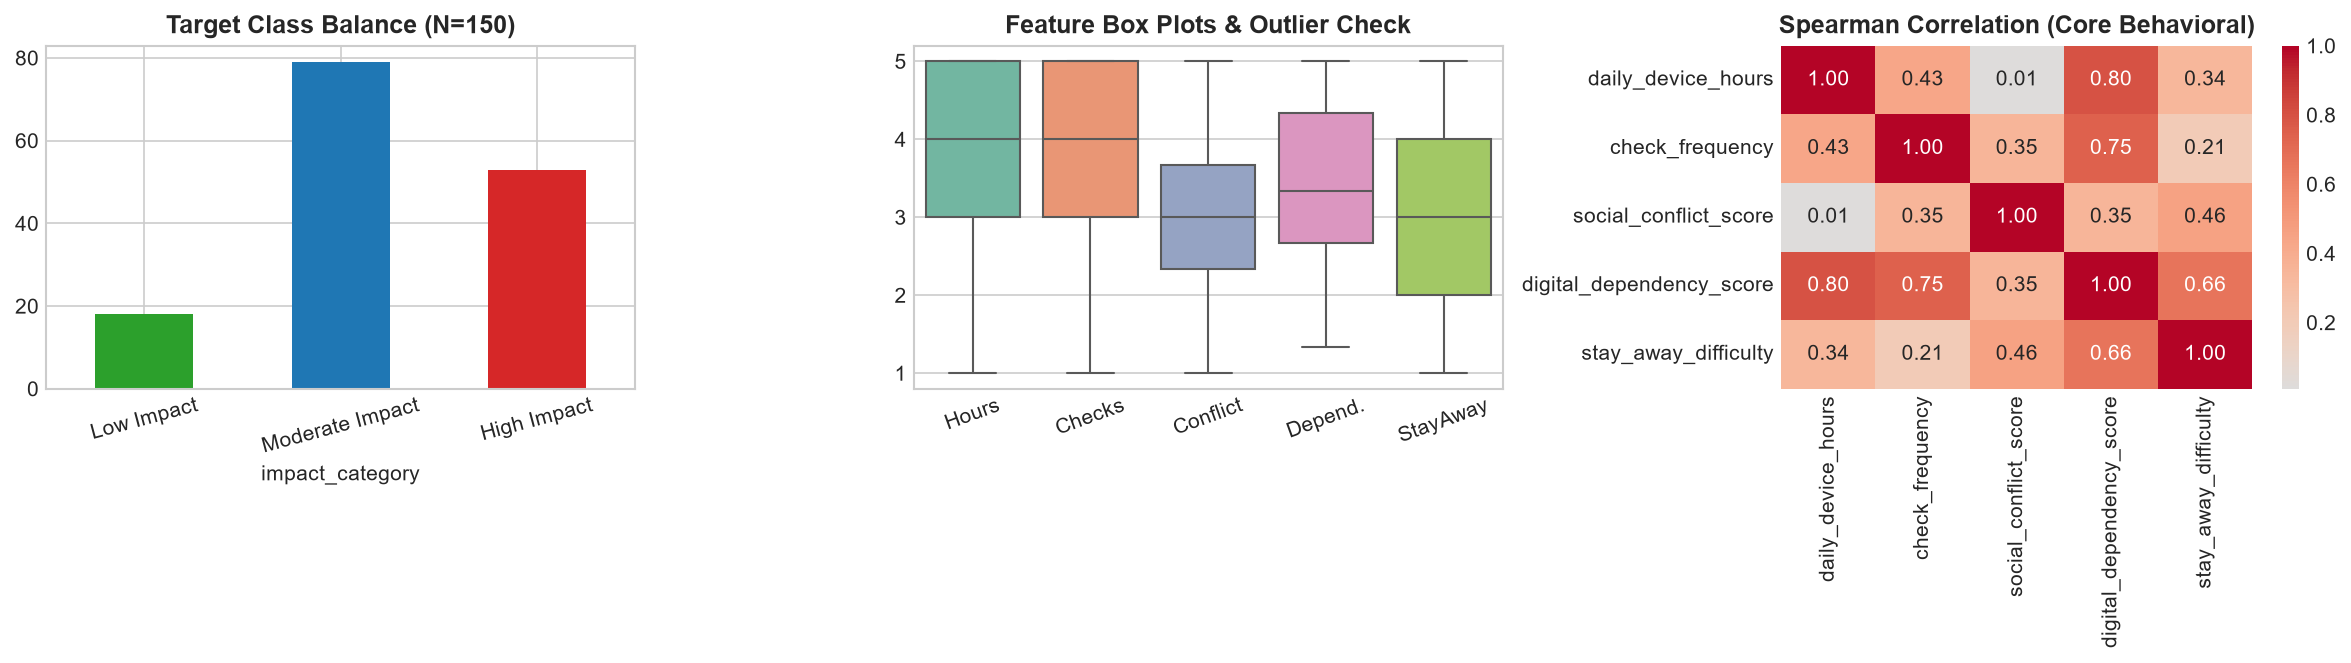

In [2]:
display(df_150[['daily_device_hours', 'check_frequency', 'social_conflict_score', 'digital_dependency_score', 'stay_away_difficulty', 'impact_category', 'data_source']].head(6))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
class_names = ['Low Impact', 'Moderate Impact', 'High Impact']
df_150['impact_category'].value_counts().reindex(class_names).plot(kind='bar', ax=axes[0], color=['#2ca02c', '#1f77b4', '#d62728'])
axes[0].set_title("Target Class Balance (N=150)", fontweight='bold')
axes[0].tick_params(axis='x', rotation=15)

num_cols = ['daily_device_hours', 'check_frequency', 'social_conflict_score', 'digital_dependency_score', 'stay_away_difficulty']
sns.boxplot(data=df_150[num_cols], ax=axes[1], palette='Set2')
axes[1].set_title("Feature Box Plots & Outlier Check", fontweight='bold')
axes[1].set_xticklabels(['Hours', 'Checks', 'Conflict', 'Depend.', 'StayAway'], rotation=20)

sns.heatmap(df_150[num_cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[2])
axes[2].set_title("Spearman Correlation (Core Behavioral)", fontweight='bold')
plt.tight_layout()
plt.show()

# Real vs Synthetic KS fidelity check
real_sub = df_150[df_150['data_source'] == 'real']
syn_sub = df_150[df_150['data_source'] != 'real']
ks_rows = [{'Feature': c, 'KS Stat': round(ks_2samp(real_sub[c], syn_sub[c]).statistic, 4),
            'p-value': round(ks_2samp(real_sub[c], syn_sub[c]).pvalue, 4)} for c in num_cols]
pd.DataFrame(ks_rows)

## Phase II: Preprocessing & Feature Configurations
- **Config A (18 Atomic Features):** Gender, 5 one-hot academic years, 6 Likert behavioral items, 6 one-hot primary activities.
- **Config B (14 Composite Features):** Replaces raw behavioral items with normalized `social_conflict_score` $\in [1, 5]$ and `digital_dependency_score` $\in [1, 5]$.
- **Target Isolation:** `academic_impact_avg`, `impact_category`, `impact_encoded`, and Q6–Q8 are strictly excluded.

In [3]:
config_a = [
    'gender_encoded',
    'year_First year', 'year_Second year', 'year_Third year', 'year_Fourth year', 'year_Other',
    'daily_device_hours', 'check_frequency',
    'phone_with_family', 'conversation_interruption', 'social_complaints', 'stay_away_difficulty',
    'activity_Communication and messaging', 'activity_Educational activities',
    'activity_Online gaming', 'activity_Other', 'activity_Social media',
    'activity_Watching videos and entertainment'
]
config_b = [
    'gender_encoded',
    'year_First year', 'year_Second year', 'year_Third year', 'year_Fourth year', 'year_Other',
    'social_conflict_score', 'digital_dependency_score',
    'activity_Communication and messaging', 'activity_Educational activities',
    'activity_Online gaming', 'activity_Other', 'activity_Social media',
    'activity_Watching videos and entertainment'
]
forbidden = {'academic_impact_avg', 'impact_category', 'impact_encoded', 'record_id', 'data_source', 'Timestamp'}
assert not forbidden.intersection(config_a) and not forbidden.intersection(config_b)
print(f"Verified zero target leakage | Config A: {len(config_a)} features | Config B: {len(config_b)} features")

Verified zero target leakage | Config A: 18 features | Config B: 14 features


## Phase III: Supervised KNN Classification
Stratified 5-Fold CV with `StandardScaler` inside `Pipeline` ($K \in [3, 15]$, uniform/distance, Euclidean/Manhattan), evaluated on the untouched 16-record genuine holdout against a Majority-Class Baseline.

                                       Model    K   Weights     Metric CV Macro F1  Test Acc  Test Macro F1  F1 Low  F1 Mod  F1 High
0         Augmented Train (N=134) | Config A   15  distance  manhattan      0.5976    0.6250         0.4091     0.0  0.7273      0.5
1         Augmented Train (N=134) | Config B    9  distance  euclidean      0.5754    0.3125         0.1667     0.0  0.5000      0.0
2             Genuine Only (N=38) | Config A    9   uniform  euclidean      0.3014    0.5625         0.2400     0.0  0.7200      0.0
3             Genuine Only (N=38) | Config B   11   uniform  manhattan      0.3231    0.6875         0.4000     0.0  0.8000      0.4
4  Majority-Class Baseline (Always Moderate)  N/A       N/A        N/A         N/A    0.6250         0.2564     0.0  0.7692      0.0


<cell>:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


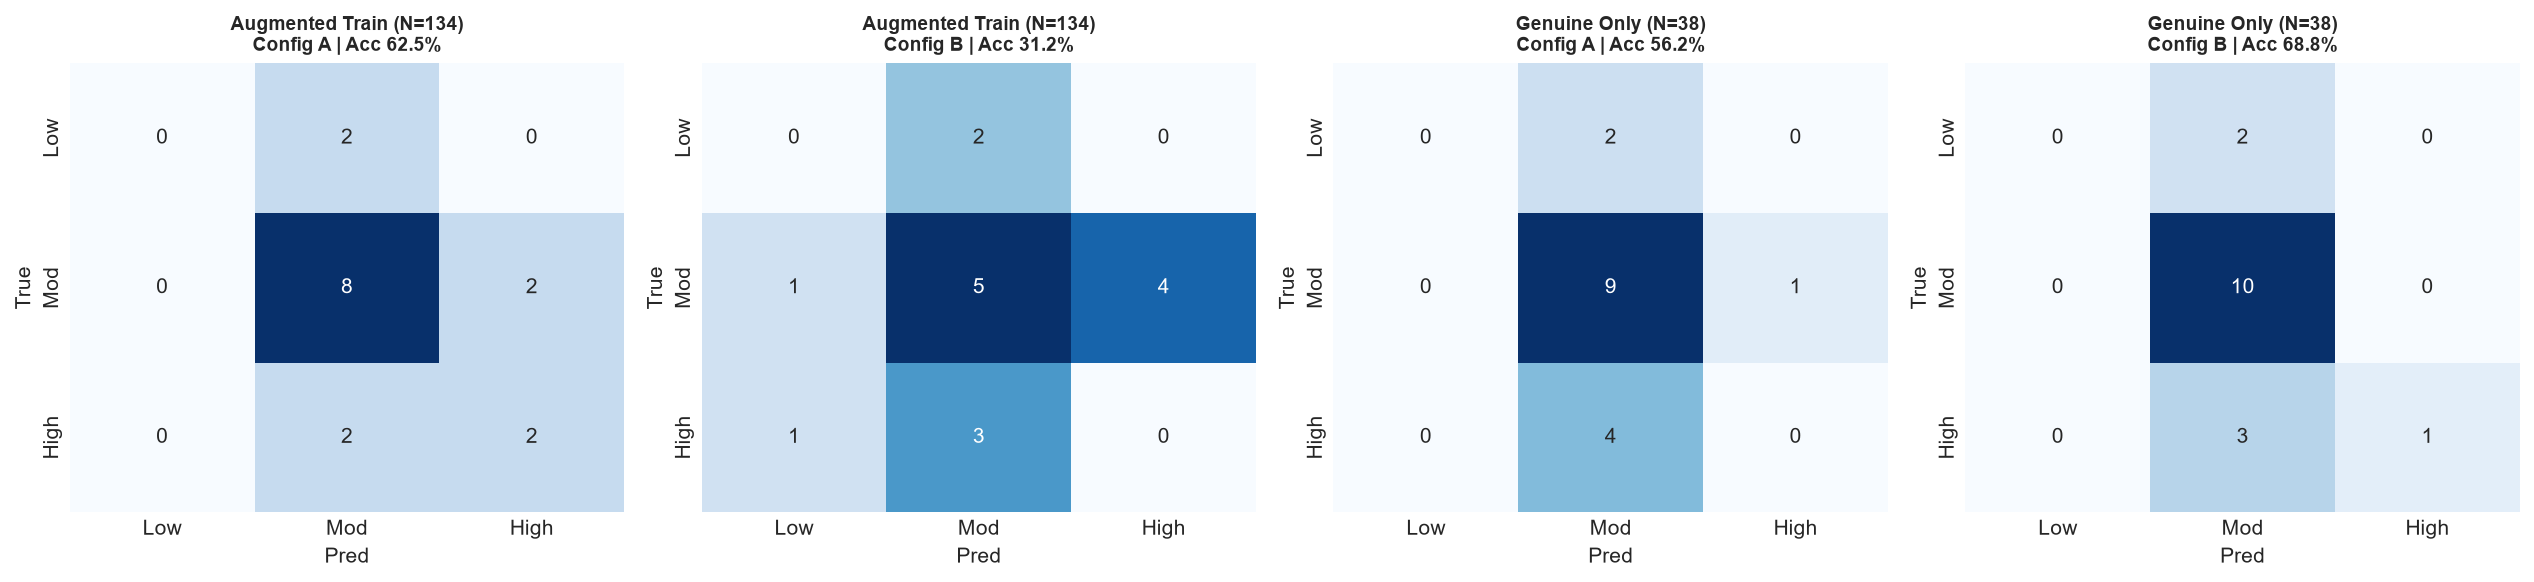

In [4]:
experiments = [
    ('Augmented Train (N=134) | Config A', df_tr_aug, config_a),
    ('Augmented Train (N=134) | Config B', df_tr_aug, config_b),
    ('Genuine Only (N=38) | Config A', df_tr_gen, config_a),
    ('Genuine Only (N=38) | Config B', df_tr_gen, config_b)
]
param_grid = {'knn__n_neighbors': [3, 5, 7, 9, 11, 13, 15], 'knn__weights': ['uniform', 'distance'], 'knn__metric': ['euclidean', 'manhattan']}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
y_test = df_test['impact_encoded'].values
knn_rows, cms = [], []

for name, tr_df, feats in experiments:
    grid = GridSearchCV(Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())]),
                        param_grid, cv=cv, scoring='f1_macro', n_jobs=1)
    grid.fit(tr_df[feats].values, tr_df['impact_encoded'].values)
    y_pred = grid.best_estimator_.predict(df_test[feats].values)
    _, _, f1_c, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1, 2], zero_division=0)
    cms.append((name, confusion_matrix(y_test, y_pred, labels=[0, 1, 2]), accuracy_score(y_test, y_pred), f1_score(y_test, y_pred, average='macro', zero_division=0)))
    knn_rows.append({
        'Model': name, 'K': grid.best_params_['knn__n_neighbors'],
        'Weights': grid.best_params_['knn__weights'], 'Metric': grid.best_params_['knn__metric'],
        'CV Macro F1': round(grid.best_score_, 4),
        'Test Acc': round(accuracy_score(y_test, y_pred), 4),
        'Test Macro F1': round(f1_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'F1 Low': round(f1_c[0], 4), 'F1 Mod': round(f1_c[1], 4), 'F1 High': round(f1_c[2], 4)
    })

y_maj = np.full_like(y_test, 1)
_, _, f1_m, _ = precision_recall_fscore_support(y_test, y_maj, labels=[0, 1, 2], zero_division=0)
knn_rows.append({
    'Model': 'Majority-Class Baseline (Always Moderate)', 'K': 'N/A', 'Weights': 'N/A', 'Metric': 'N/A',
    'CV Macro F1': 'N/A', 'Test Acc': round(accuracy_score(y_test, y_maj), 4),
    'Test Macro F1': round(f1_score(y_test, y_maj, average='macro', zero_division=0), 4),
    'F1 Low': round(f1_m[0], 4), 'F1 Mod': round(f1_m[1], 4), 'F1 High': round(f1_m[2], 4)
})
display(pd.DataFrame(knn_rows))

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (name, cm, acc, mf1) in zip(axes, cms):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Low', 'Mod', 'High'], yticklabels=['Low', 'Mod', 'High'], ax=ax)
    ax.set_title(f"{name.split('|')[0].strip()}\n{name.split('|')[1].strip()} | Acc {acc:.1%}", fontsize=9, fontweight='bold')
    ax.set_xlabel("Pred"); ax.set_ylabel("True")
plt.tight_layout()
plt.show()

## Phase IV: K-Means Clustering ($K \in [2, 6]$)
Fit K-Means without target labels, inspect Elbow WCSS & Silhouette curves, visualize $K=3$ clusters in 2D PCA space, and inspect descriptive cluster profiles & boundary observations.

          Config  K  Inertia  Silhouette     ARI     NMI
0  Config A (18)  2  2439.37      0.1201 -0.0008  0.0046
1  Config A (18)  3  2245.43      0.1519  0.0078  0.0057
2  Config A (18)  4  2072.65      0.1495  0.0625  0.0720
3  Config A (18)  5  1925.26      0.1761  0.0159  0.0294
4  Config A (18)  6  1724.23      0.2020  0.0784  0.0743
5  Config B (14)  2  1842.21      0.1649  0.0001  0.0050
6  Config B (14)  3  1644.67      0.1904  0.0061  0.0043
7  Config B (14)  4  1481.84      0.2169  0.0625  0.0720
8  Config B (14)  5  1332.88      0.2232  0.0195  0.0273
9  Config B (14)  6  1171.84      0.2199  0.0148  0.0329
         Size  daily_device_hours  check_frequency  social_conflict_score  digital_dependency_score  stay_away_difficulty   Dominant Class
Cluster                                                                                                                                   
1          85                3.51             3.92                   2.96                      

<cell>:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


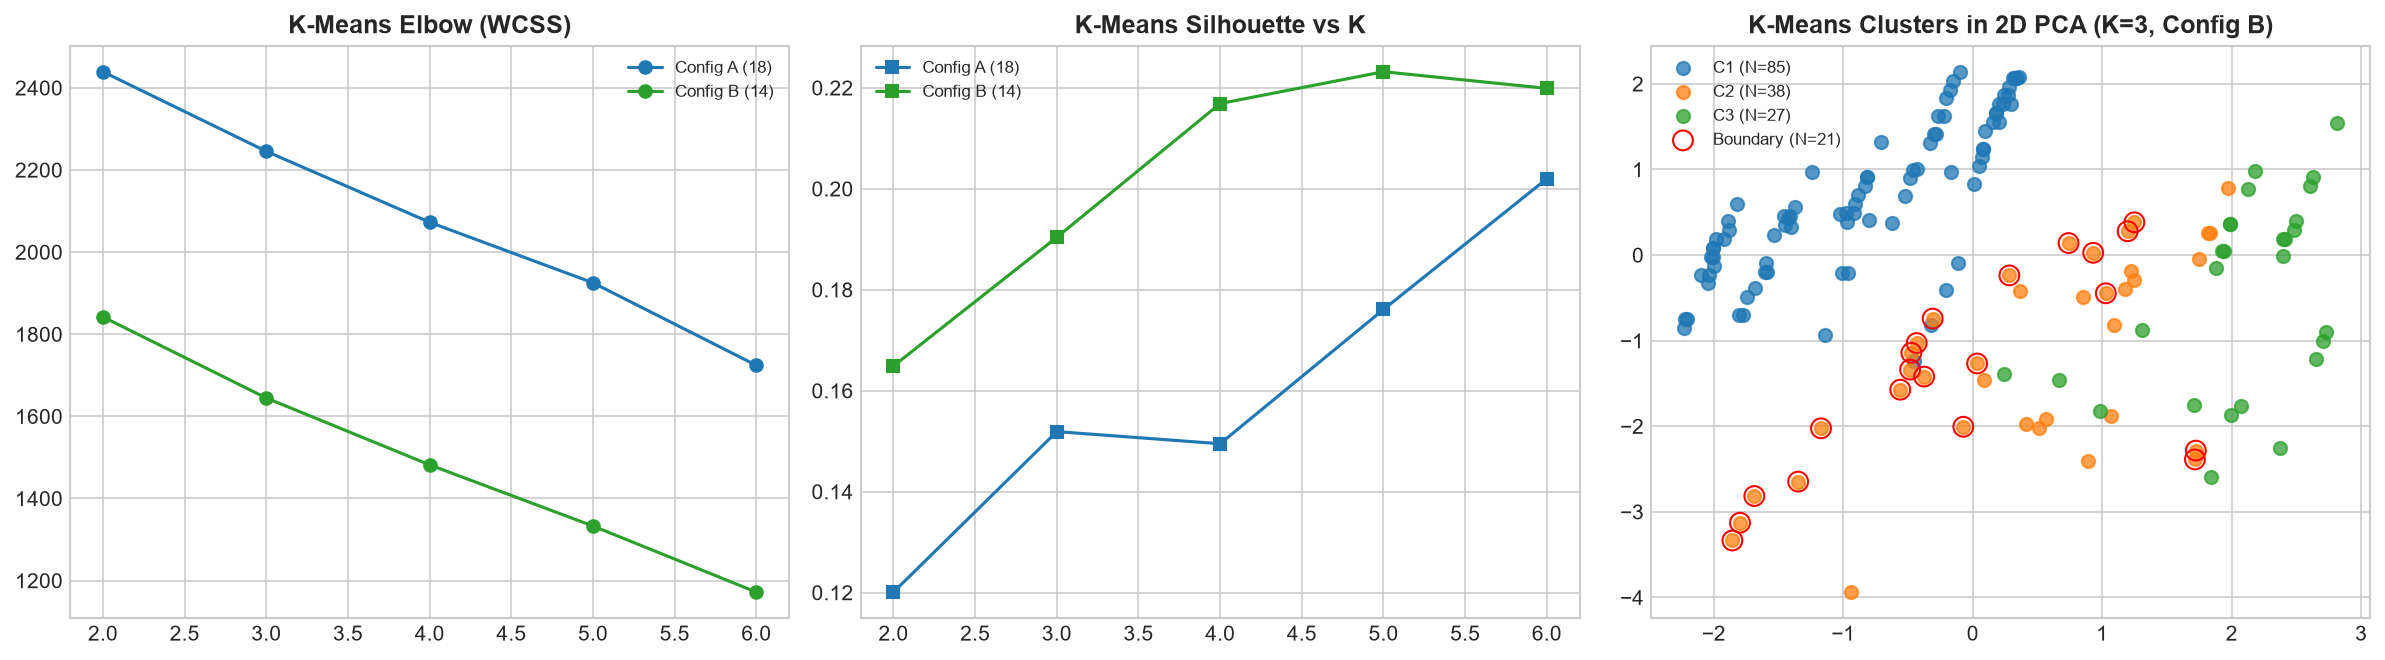

In [5]:
scaler = StandardScaler()
X_150_b = scaler.fit_transform(df_150[config_b])
X_150_a = scaler.fit_transform(df_150[config_a])
y_150 = df_150['impact_category'].values

km_sweep = []
for cfg_lbl, X_mat in [('Config A (18)', X_150_a), ('Config B (14)', X_150_b)]:
    for k in range(2, 7):
        km = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=SEED).fit(X_mat)
        km_sweep.append({'Config': cfg_lbl, 'K': k, 'Inertia': round(km.inertia_, 2),
                         'Silhouette': round(silhouette_score(X_mat, km.labels_), 4),
                         'ARI': round(adjusted_rand_score(y_150, km.labels_), 4),
                         'NMI': round(normalized_mutual_info_score(y_150, km.labels_), 4)})
df_km_sw = pd.DataFrame(km_sweep)
display(df_km_sw)

km3 = KMeans(n_clusters=3, init='k-means++', n_init=20, random_state=SEED)
km_lbls = km3.fit_predict(X_150_b) + 1
sil_s = silhouette_samples(X_150_b, km_lbls - 1)
pca = PCA(n_components=2, random_state=SEED)
Xp = pca.fit_transform(X_150_b)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for cfg_lbl, col in [('Config A (18)', '#1f77b4'), ('Config B (14)', '#2ca02c')]:
    s = df_km_sw[df_km_sw['Config'] == cfg_lbl]
    axes[0].plot(s['K'], s['Inertia'], marker='o', label=cfg_lbl, color=col)
    axes[1].plot(s['K'], s['Silhouette'], marker='s', label=cfg_lbl, color=col)
axes[0].set_title("K-Means Elbow (WCSS)", fontweight='bold'); axes[0].legend(fontsize=8)
axes[1].set_title("K-Means Silhouette vs K", fontweight='bold'); axes[1].legend(fontsize=8)

for cid, col in [(1, '#1f77b4'), (2, '#ff7f0e'), (3, '#2ca02c')]:
    m = km_lbls == cid
    axes[2].scatter(Xp[m, 0], Xp[m, 1], c=col, label=f"C{cid} (N={m.sum()})", alpha=0.75, s=40)
axes[2].scatter(Xp[sil_s < 0, 0], Xp[sil_s < 0, 1], facecolors='none', edgecolors='red', s=90, label=f"Boundary (N={(sil_s<0).sum()})")
axes[2].set_title("K-Means Clusters in 2D PCA (K=3, Config B)", fontweight='bold'); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

df_p = df_150.copy()
df_p['Cluster'] = km_lbls
prof_tbl = df_p.groupby('Cluster')[num_cols].mean().round(2)
prof_tbl.insert(0, 'Size', df_p['Cluster'].value_counts().sort_index())
prof_tbl['Dominant Class'] = pd.crosstab(df_p['Cluster'], df_p['impact_category']).idxmax(axis=1)
display(prof_tbl)

## Phase V: Agglomerative Hierarchical Clustering (Single, Complete, Average, Ward)
Compare all 4 linkage methods at $K=3$ (Config B), visualize dendrograms, and inspect cluster counts and dominant classes.

    Linkage  K  Silhouette     ARI     NMI Cluster Sizes
0    Single  3      0.2491  0.0332  0.0351   [136, 9, 5]
1  Complete  3      0.2056  0.0398  0.0250  [113, 32, 5]
2   Average  3      0.2491  0.0332  0.0351   [136, 9, 5]
3      Ward  3      0.1499  0.0177  0.0516  [75, 62, 13]


<cell>:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


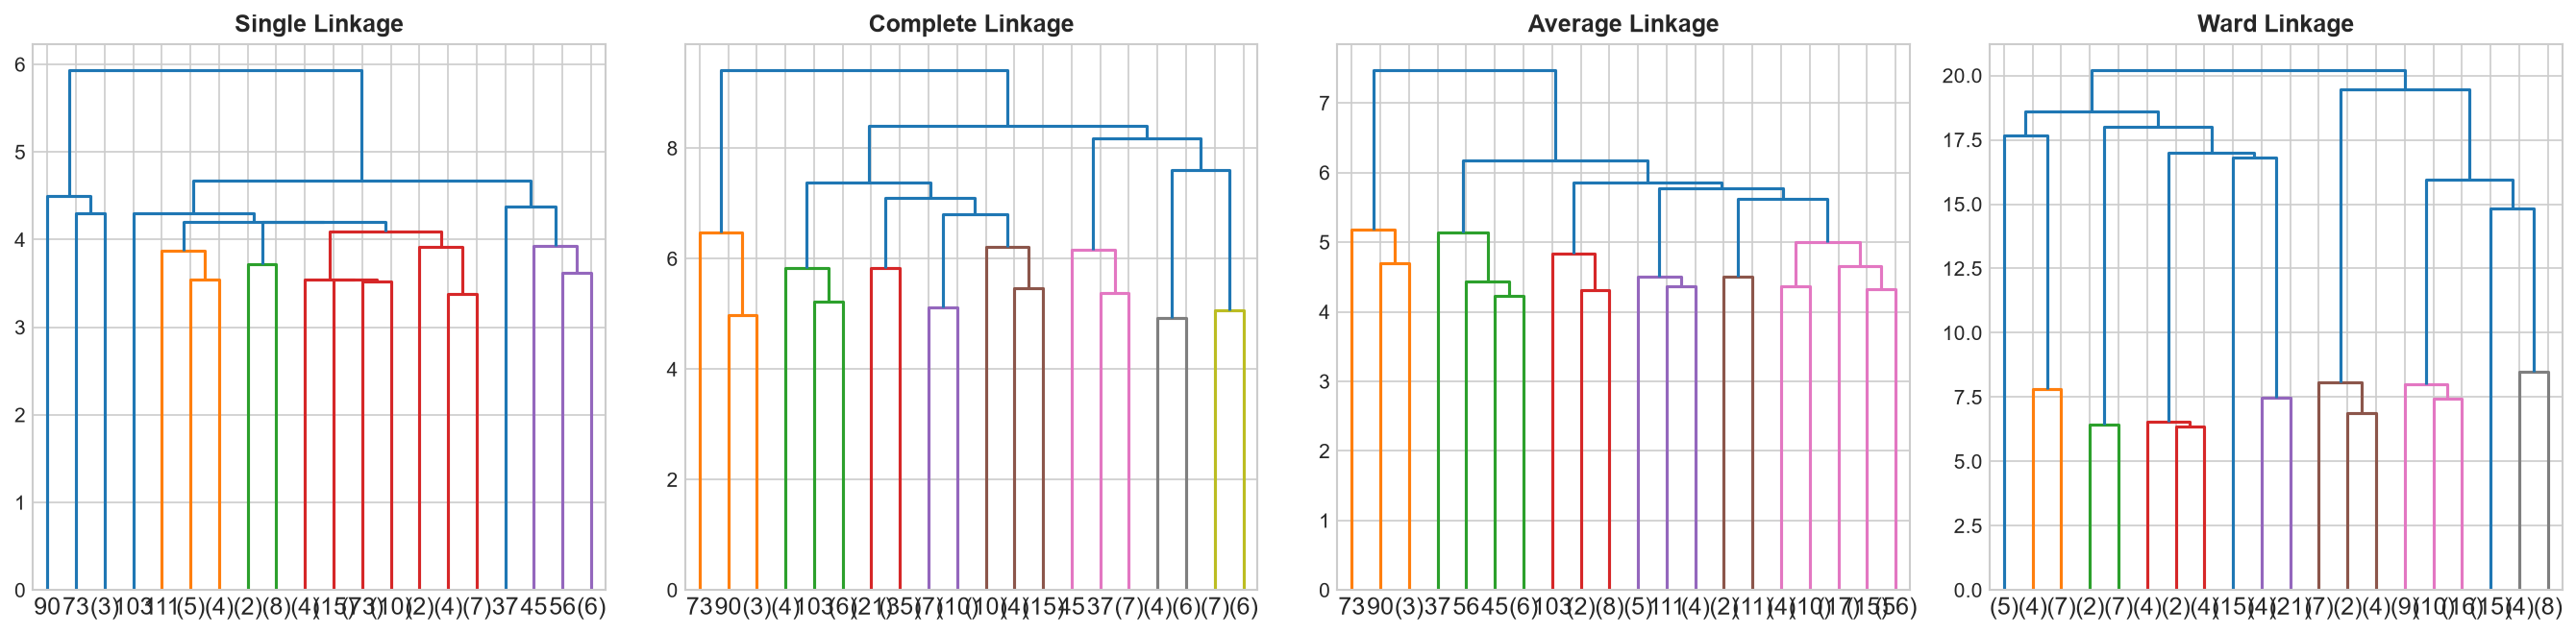

In [6]:
agg_rows, brk_rows = [], []
for link in ['single', 'complete', 'average', 'ward']:
    lbls = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X_150_b) + 1
    agg_rows.append({
        'Linkage': link.capitalize(), 'K': 3,
        'Silhouette': round(silhouette_score(X_150_b, lbls - 1), 4),
        'ARI': round(adjusted_rand_score(y_150, lbls), 4),
        'NMI': round(normalized_mutual_info_score(y_150, lbls), 4),
        'Cluster Sizes': sorted([int((lbls == c).sum()) for c in [1, 2, 3]], reverse=True)
    })
    for cid in [1, 2, 3]:
        m = lbls == cid
        dom = pd.Series(y_150[m]).value_counts().idxmax()
        brk_rows.append({'Linkage': link.capitalize(), 'Cluster': f"C{cid}", 'Size': int(m.sum()), 'Dominant Class': dom})

display(pd.DataFrame(agg_rows))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, link in zip(axes, ['single', 'complete', 'average', 'ward']):
    Z = linkage(X_150_b, method=link, metric='euclidean')
    dendrogram(Z, ax=ax, truncate_mode='lastp', p=20, show_leaf_counts=True, color_threshold=0.7 * max(Z[:, 2]))
    ax.set_title(f"{link.capitalize()} Linkage", fontweight='bold')
plt.tight_layout()
plt.show()

## Phase VI: Comparative Analysis (KNN vs. K-Means vs. Agglomerative)

| Evaluation Criteria | KNN | K-Means | Agglomerative |
| :--- | :--- | :--- | :--- |
| **Learning type** | Supervised | Unsupervised | Unsupervised |
| **Labels used during fitting** | Yes (`impact_encoded`) | No (strictly excluded) | No (strictly excluded) |
| **Accuracy on held-out labels ($N=16$)** | 68.75% (Genuine Config B) / 62.50% (Aug. Config A; Baseline = 62.50%) | Not directly applicable | Not directly applicable |
| **Silhouette Score ($K=3$, Config B)** | Not applicable | 0.1904 (Full 150) / 0.2194 (Genuine 54) | Ward: 0.1499 (150) / 0.2298 (54); Single/Avg: 0.2491 (chaining) |
| **ARI / NMI (Full 150, $K=3$, Config B)** | Not applicable | ARI = 0.0061 / NMI = 0.0043 | Ward: ARI = 0.0177 / NMI = 0.0516; Complete: ARI = 0.0398 / NMI = 0.0250 |
| **Main observations** | Captures majority (`Moderate`) and some `High`, but 0% `Low Impact` recall; genuine Config B generalized best. | Config B improves separation; clusters reflect usage/platform habits rather than impact tiers. | Single & Average linkages chain (`136/9/5`), while Ward creates balanced groupings (`75/62/13`). |
| **Limitations** | Small holdout ($N=16$), class imbalance, synthetic data did not improve holdout accuracy. | 21 negative-silhouette boundary points; low post-hoc alignment with subjective impact labels. | Highly sensitive to linkage rule; low post-hoc label alignment. |